In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(67)

Questão 1. Box-Muller

In [2]:
def Normal_BoxMuller():
    u1 = np.random.uniform()
    u2 = np.random.uniform()

    u_2pi = 2*np.pi*u2
    t = -np.log(u1)

    z1 = np.sqrt(2*t)*np.cos(u_2pi)
    z2 = np.sqrt(2*t)*np.sin(u_2pi)

    return z1,z2

In [3]:
#Densidade da Normal Padrão
def normal(x):
    num = np.exp(-(x**2)/2)
    den = np.sqrt(2*np.pi)
    return num/den

In [4]:
N = 10**4 #Valor usado nos labs 

Normal_z1 = []
Normal_z2 = []

for i in range(N):
    z1,z2 = Normal_BoxMuller()
    Normal_z1.append(z1)
    Normal_z2.append(z2)

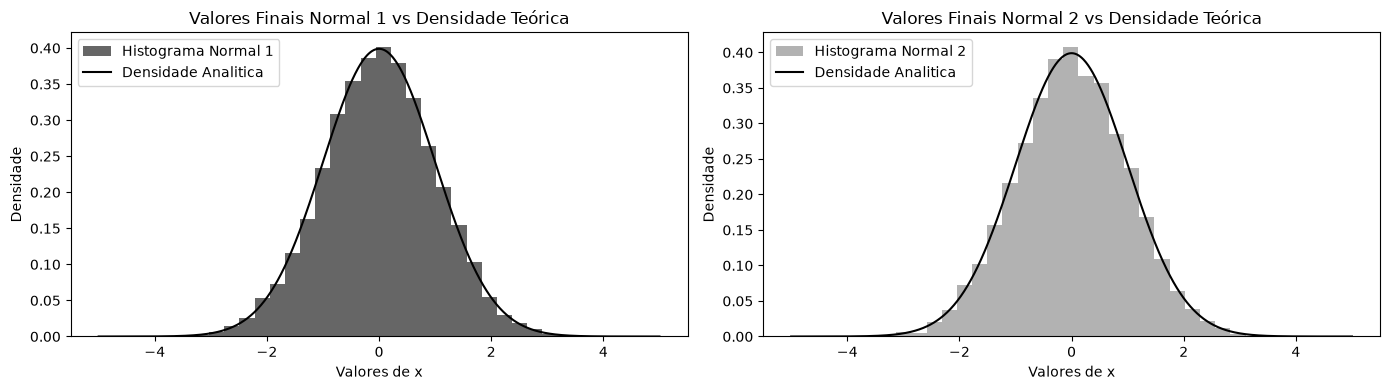

In [5]:
plt.figure(figsize=(14,4))

eixo_x = np.linspace(-5,5,1000)

plt.subplot(1,2,1)
plt.hist(Normal_z1,bins=30, density=True, alpha=0.6, color='black', label='Histograma Normal 1')
plt.plot(eixo_x, normal(eixo_x),label='Densidade Analitica', color ='black')

plt.xlabel('Valores de x')
plt.ylabel('Densidade')
plt.title(f'Valores Finais Normal 1 vs Densidade Teórica')
plt.legend(loc = 'upper left')

plt.subplot(1,2,2)
plt.hist(Normal_z2, bins=30, density=True, alpha=0.6, color='grey', label='Histograma Normal 2')
plt.plot(eixo_x, normal(eixo_x),label='Densidade Analitica', color = 'black')

plt.xlabel('Valores de x')
plt.ylabel('Densidade')
plt.title(f'Valores Finais Normal 2 vs Densidade Teórica')
plt.legend(loc = 'upper left')

plt.tight_layout()
plt.show()

In [6]:
#Cálculo das médias e variâncias amostrais

media_z1 = np.mean(Normal_z1)
media_z2 = np.mean(Normal_z2)

var_z1 = np.var(Normal_z1)
var_z2 = np.var(Normal_z2)

print(media_z1,media_z2)
print(var_z1,var_z2)

0.010829025268228107 0.0029750043222283966
1.0123414585343176 0.9871845222121559


In [7]:
mi_x = 0
dp_x = 1
p_cor = 0.6
mi_y = 0
dp_y = np.sqrt(4)
n = 10000
amostra_Y = []
amostra_X = []
amostra_XY = []
for i in range(n):
    z1, z2 = Normal_BoxMuller()
    X = mi_x + dp_x * z1
    Y = mi_y + dp_y * (p_cor * z1 + np.sqrt(1 - p_cor**2) * z2)
    amostra_Y.append(Y)
    amostra_X.append(X)
    amostra_XY.append([X,Y])
    

media_amostral_X = np.mean(amostra_X)
correlacao_amostral = np.corrcoef(amostra_X, amostra_Y)[0,1]
variancia_amostral_X = np.var(amostra_X)
variancia_amostral_Y = np.var(amostra_Y)
media_amostral_Y = np.mean(amostra_Y)
print(f"A variancia amostral de X é: {variancia_amostral_X:.3f}")
print(f"A média amostral de X é: {media_amostral_X:.3f}")
print(f"A variancia amostral de Y é: {variancia_amostral_Y:.3f}")
print(f"A média amostral de Y é: {media_amostral_Y:.3f}")


print(f"A correlação amostral é: {correlacao_amostral:.3f}")

A variancia amostral de X é: 1.008
A média amostral de X é: 0.004
A variancia amostral de Y é: 4.006
A média amostral de Y é: 0.011
A correlação amostral é: 0.601


A matriz de covariancia é representador por: 
[[1.00835498 1.2079205 ]
 [1.2079205  4.00613879]]


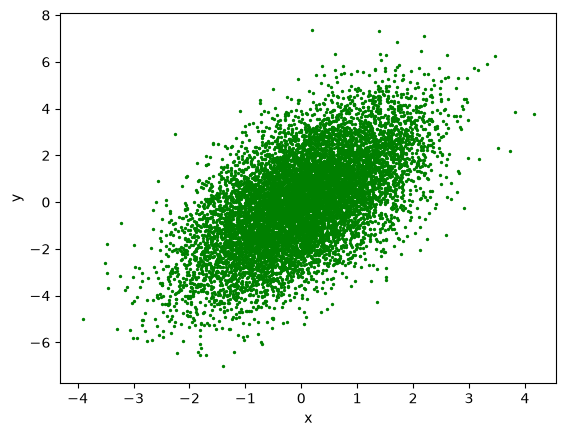

In [8]:
#Criando o gráfico de dispersão e a matri
plt.scatter(amostra_X, amostra_Y, color='green', s=2)
plt.ylabel('y')
plt.xlabel('x')
print(f"A matriz de covariancia é representador por: \n{np.cov(amostra_X, amostra_Y)}")